<a href="https://colab.research.google.com/github/illi0125/construction-ppe-checker./blob/main/Safety_Checker.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Construction Safety PPE Checker
Detects workers' protective equipment (helmet, vest, gloves, boots, goggles) and violations (`no_helmet`, `no_gloves`, ...) with **YOLOv8**, then gives a site verdict: **SAFE** or **UNSAFE**.

**Before you start:** `Runtime → Change runtime type → T4 GPU`, then `Runtime → Run all`.

Dataset: Ultralytics Construction-PPE (1,132 train / 143 val / 141 test images, 11 classes). It downloads automatically, no API key needed.

## 1. Setup

In [1]:
!pip install -q ultralytics gradio
import torch, ultralytics
print("ultralytics", ultralytics.__version__, "| GPU:", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "none (training will be slow)")

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 46.9/46.9 kB 2.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 35.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 97.6/97.6 kB 7.9 MB/s eta 0:00:00
Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.
ultralytics 8.4.179 | GPU: Tesla T4


## 2. Train
Fine-tunes YOLOv8n (pretrained on COCO). About 15–25 minutes on a T4.

In [2]:
from ultralytics import YOLO

EPOCHS = 50   # lower to 20 for a quick run

model = YOLO("yolov8n.pt")
model.train(
    data="construction-ppe.yaml",
    epochs=EPOCHS,
    imgsz=640,
    batch=16,
    patience=15,          # early stop if val mAP stops improving
    project="ppe", name="yolov8n", exist_ok=True,
    # augmentation (Ultralytics defaults, written out for clarity)
    fliplr=0.5, degrees=5.0, scale=0.5, hsv_v=0.4, mosaic=1.0,
)
RUN_DIR = str(model.trainer.save_dir)   # actual output folder (newer Ultralytics puts it under runs/detect/)
print("Saved to:", RUN_DIR)

Ultralytics 8.4.179 🚀 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=construction-ppe.yaml, degrees=5.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=50, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolov8n.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=yolov8n, nbs=64, nms=None, opset=None, optimize=False, optimizer=auto

## 3. Evaluate
Precision, recall and mAP on the held-out test split.

In [3]:
import glob, os
if "RUN_DIR" not in globals():   # e.g. after a runtime restart: find the latest training run
    RUN_DIR = os.path.dirname(os.path.dirname(max(glob.glob("/content/**/weights/best.pt", recursive=True), key=os.path.getmtime)))
best = YOLO(f"{RUN_DIR}/weights/best.pt")
metrics = best.val(data="construction-ppe.yaml", split="test")
print(f"Precision {metrics.box.mp:.3f} | Recall {metrics.box.mr:.3f} | mAP50 {metrics.box.map50:.3f} | mAP50-95 {metrics.box.map:.3f}")
print()
for i, c in enumerate(metrics.box.ap_class_index):
    print(f"{best.names[int(c)]:10s} AP50 = {metrics.box.ap50[i]:.3f}")

Ultralytics 8.4.179 🚀 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
Model summary (fused): 73 layers, 3,135,137 parameters, 0 gradients, 8.7 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 2246.2±1388.0 MB/s, size: 96.5 KB)
val: Scanning /content/datasets/construction-ppe/labels/test... 141 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 141/141 2.0Kit/s 0.1s
val: New cache created: /content/datasets/construction-ppe/labels/test.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 9/9 2.4it/s 3.8s
                   all        141       1251      0.579      0.534      0.534      0.256
                helmet        110        192      0.904      0.922      0.942      0.485
                gloves         75        163      0.759      0.755      0.758      0.359
                  vest        111        178      0.827      0.876      0.901      0.551
                 boots         75        211      0

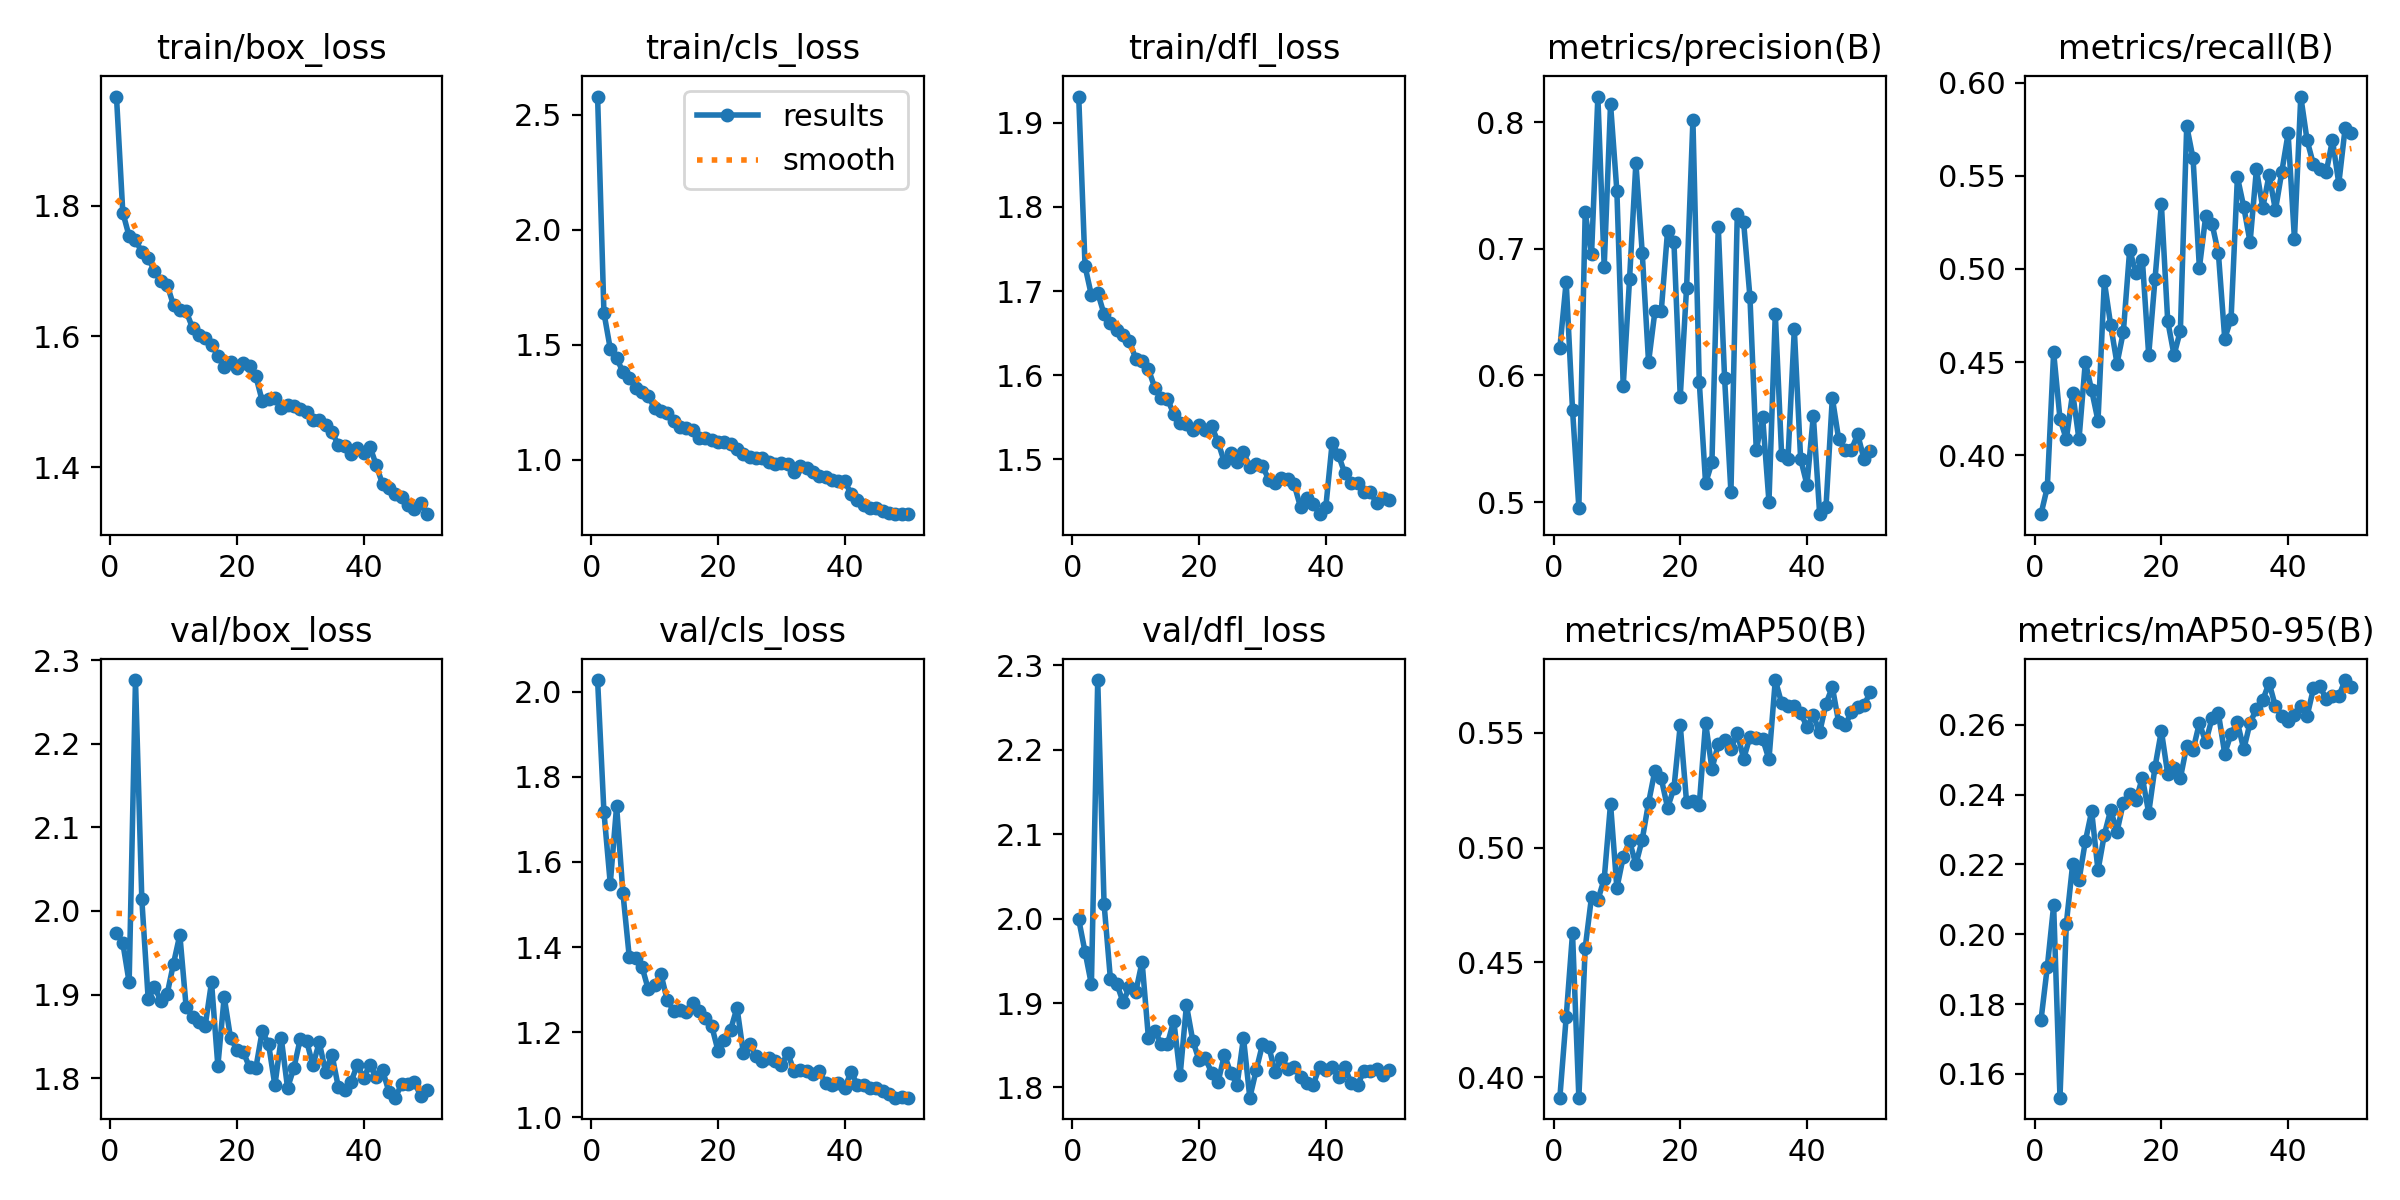

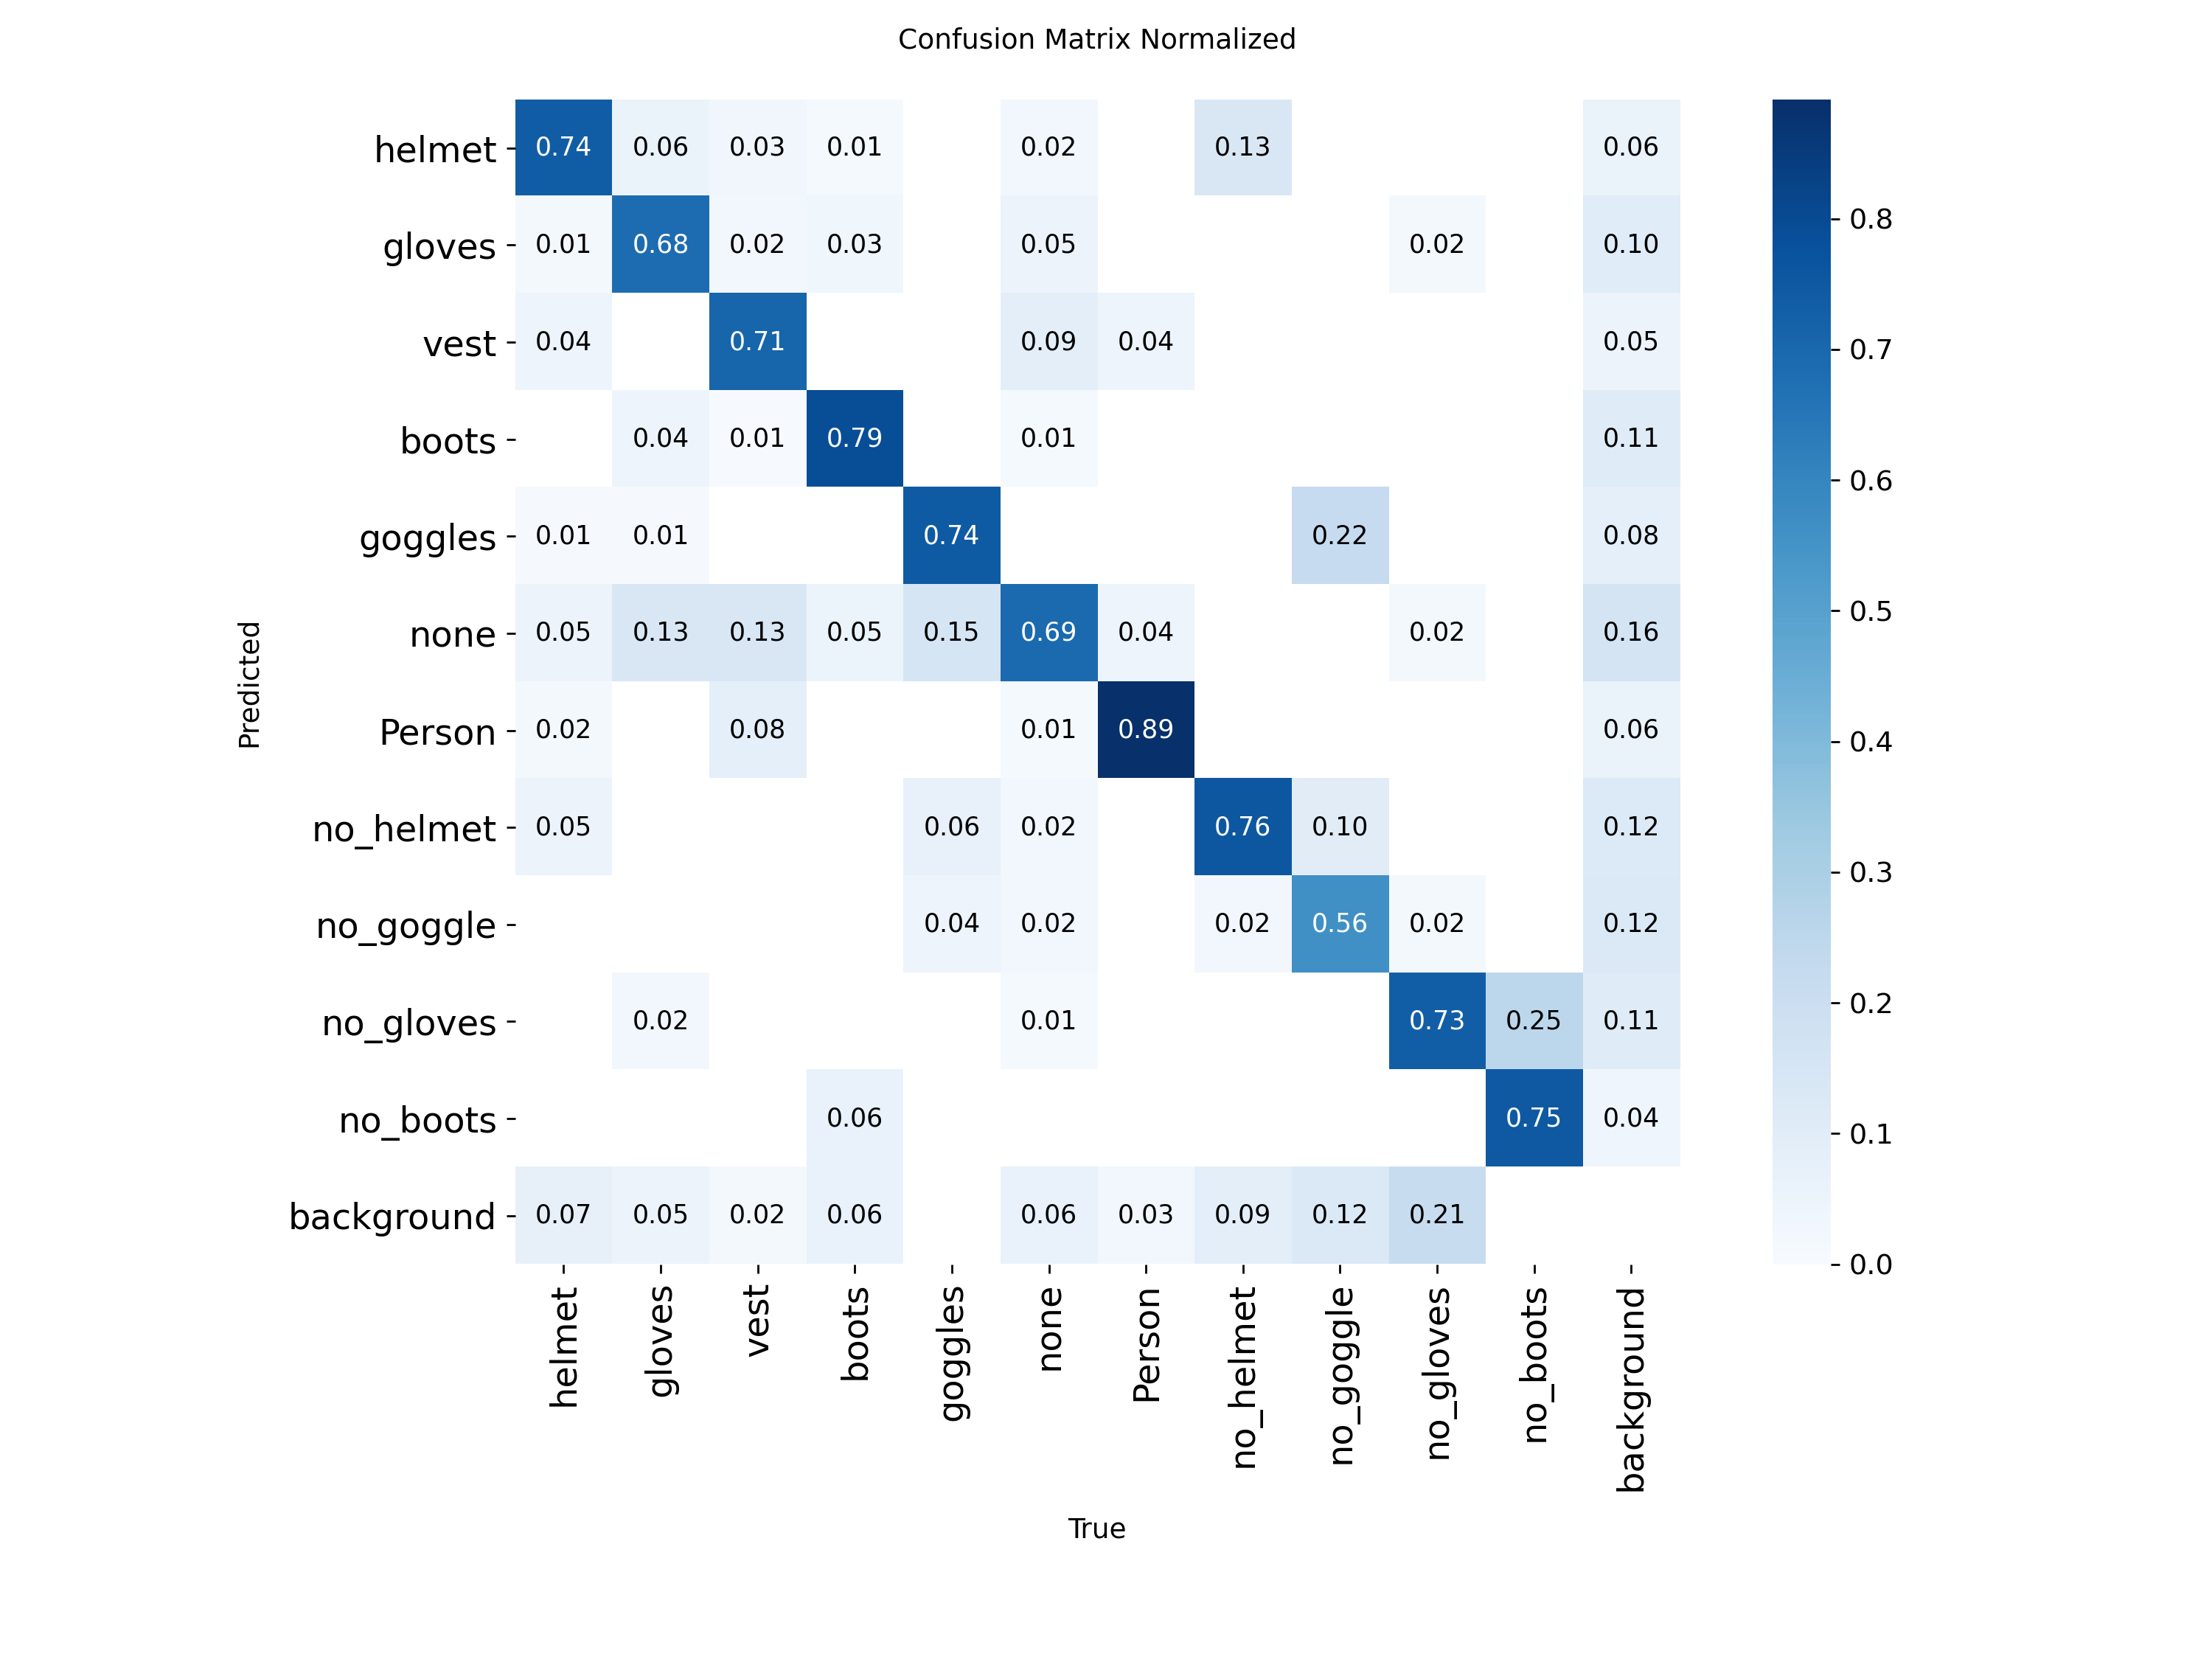

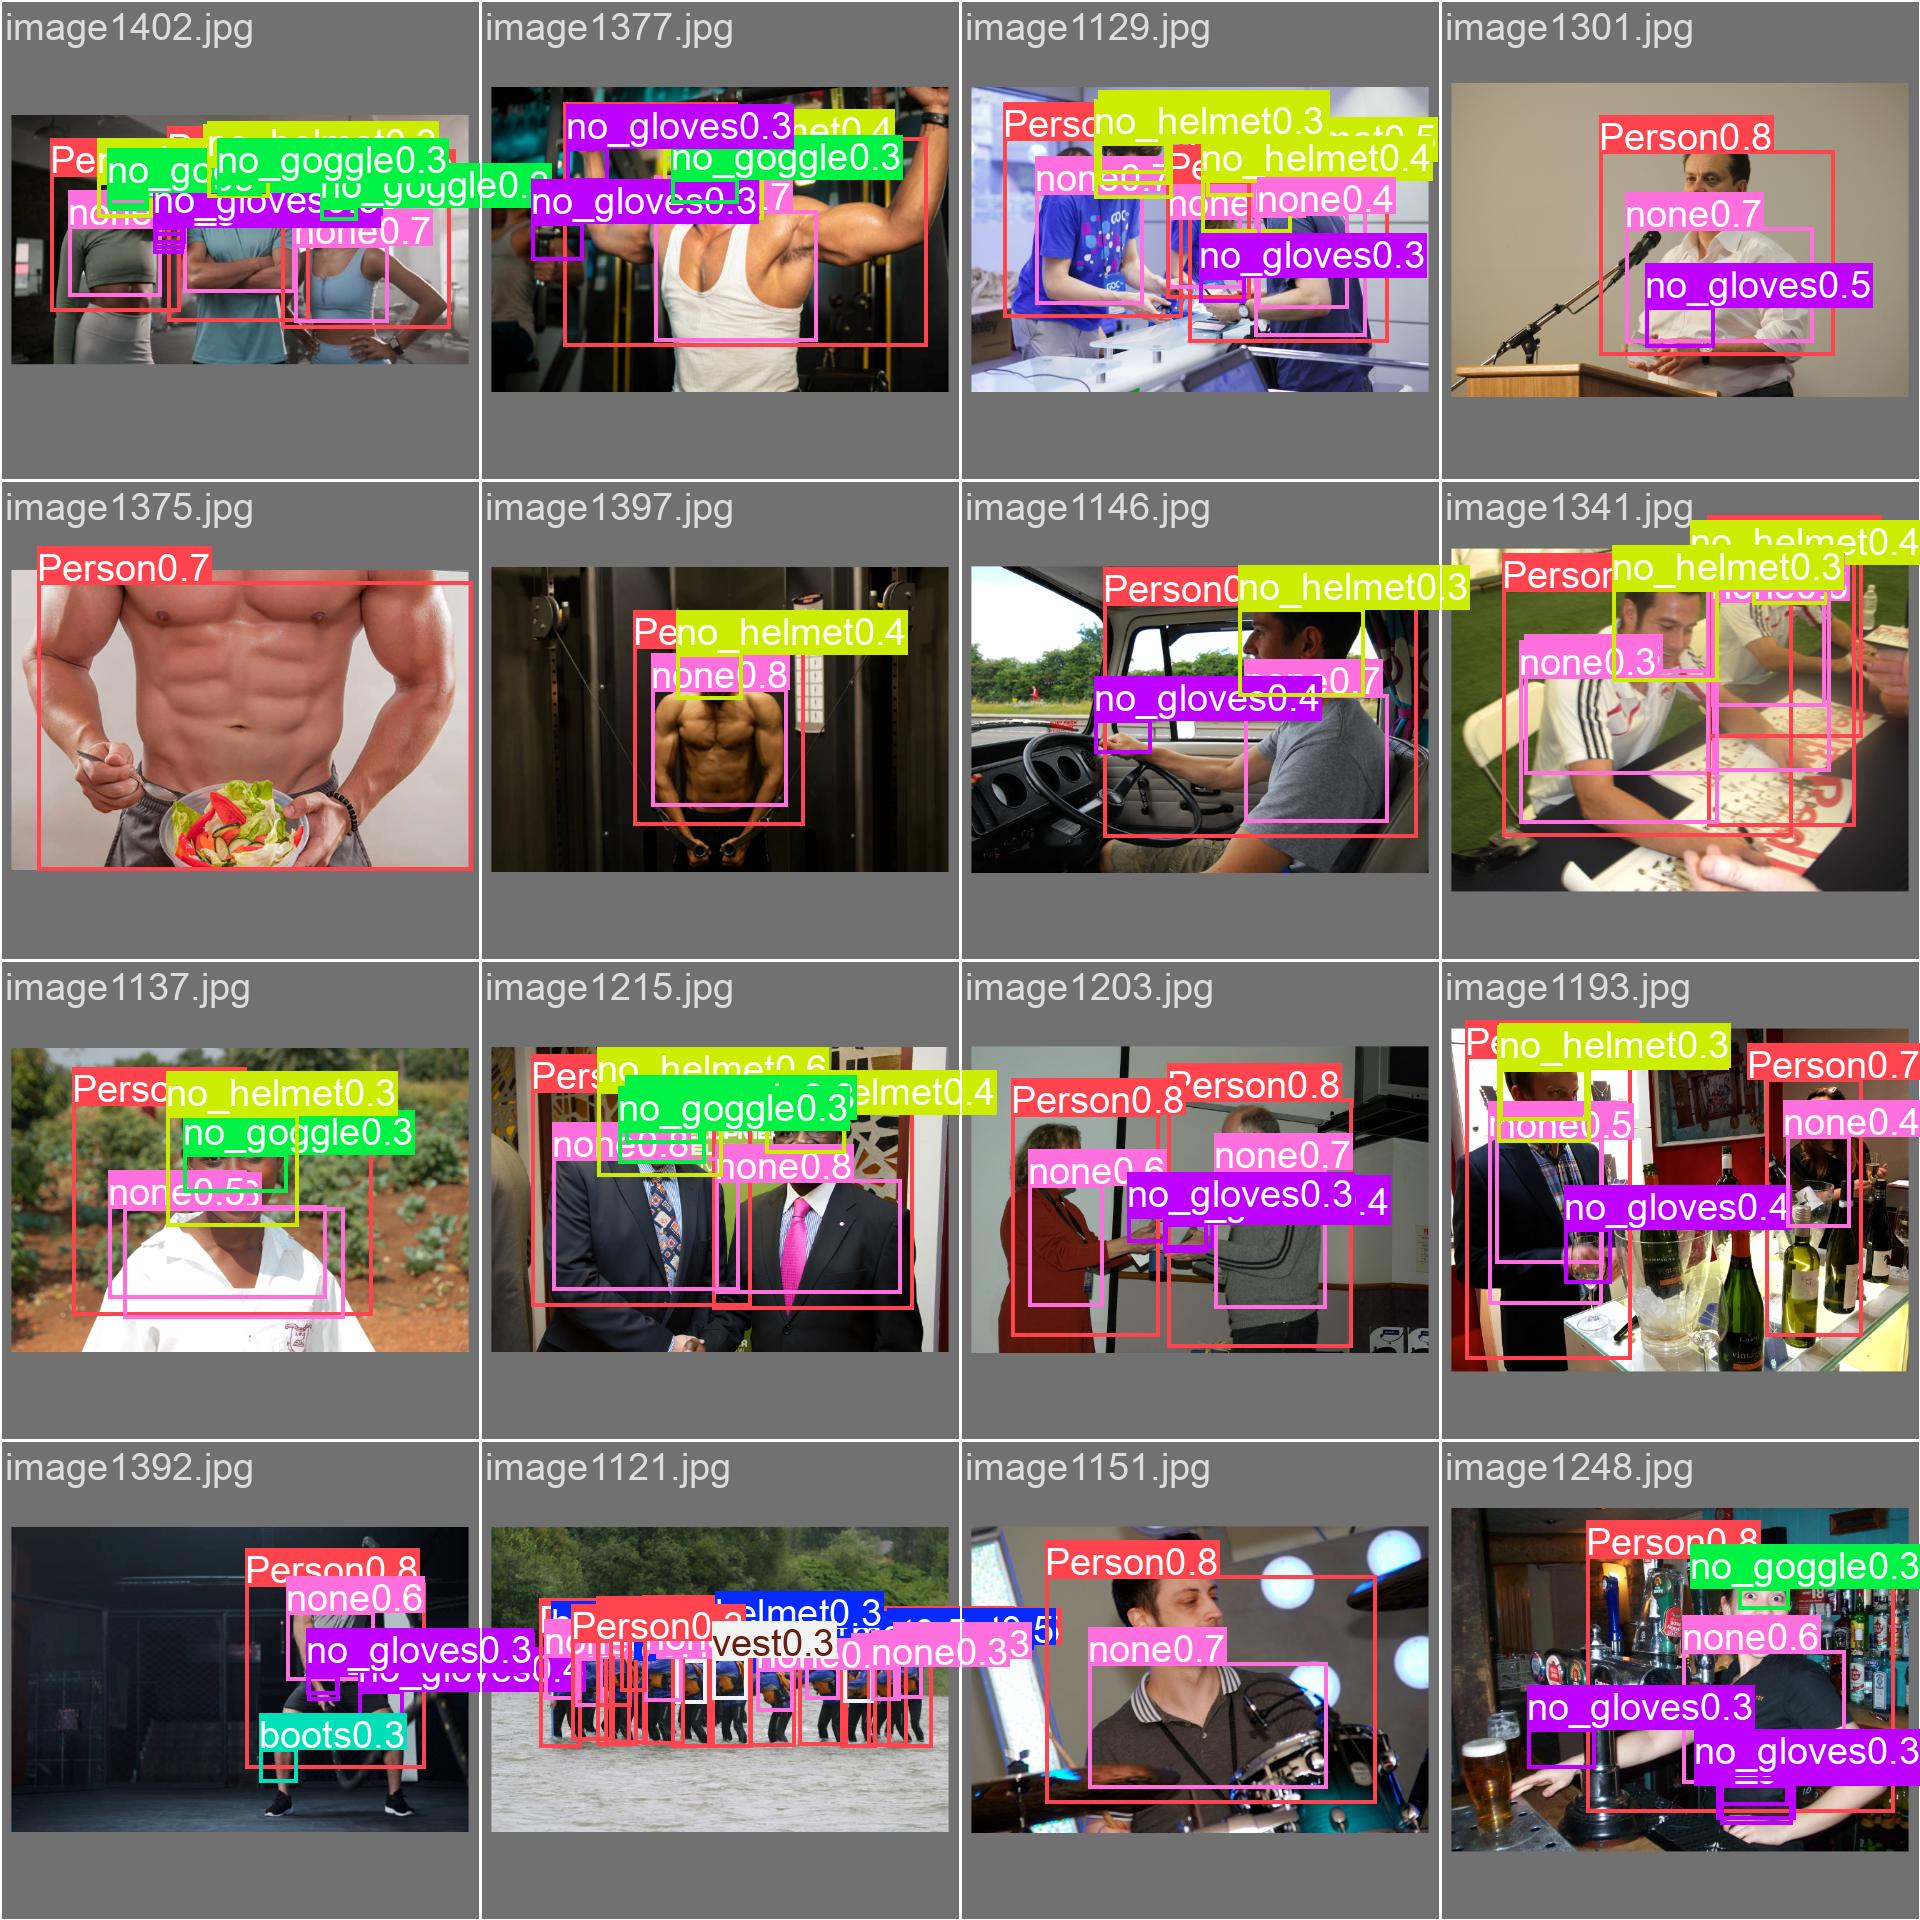

In [4]:
from IPython.display import Image, display
for f in ["results.png", "confusion_matrix_normalized.png", "val_batch0_pred.jpg"]:
    display(Image(f"{RUN_DIR}/{f}", width=900))

## 4. Safety verdict
Turns raw detections into a site check: any `no_*` class means a violation.

image1.jpeg | SAFE | workers: 1 | all PPE present


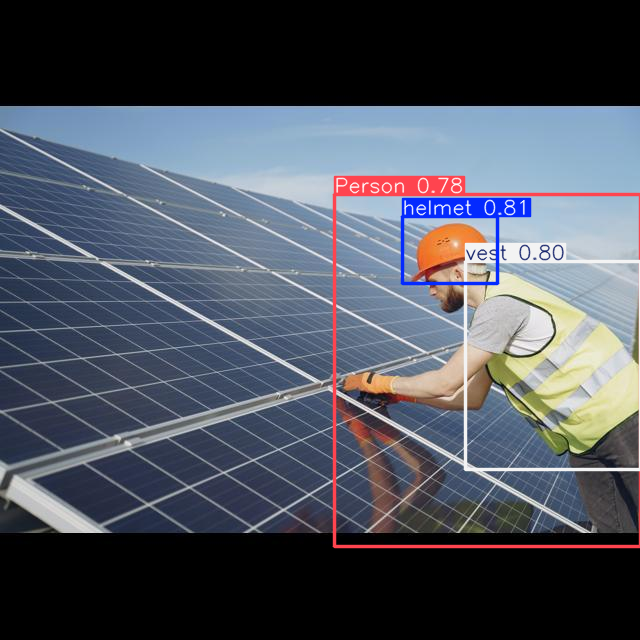

image10.jpeg | SAFE | workers: 3 | all PPE present


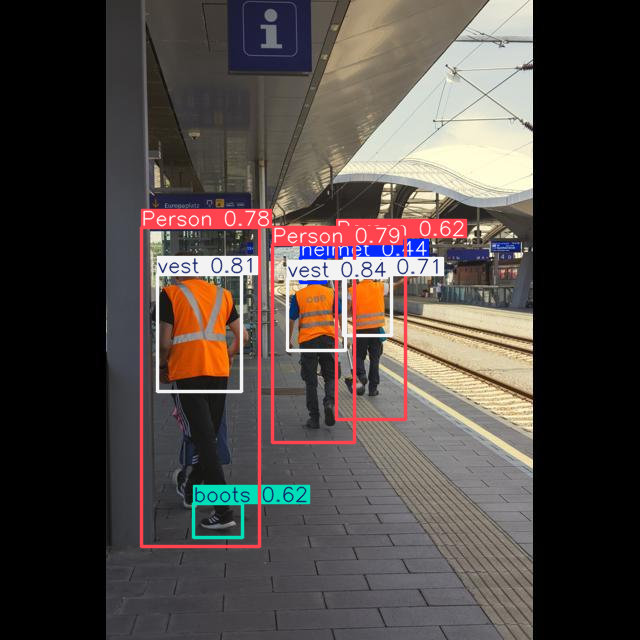

image1003.jpg | SAFE | workers: 1 | all PPE present


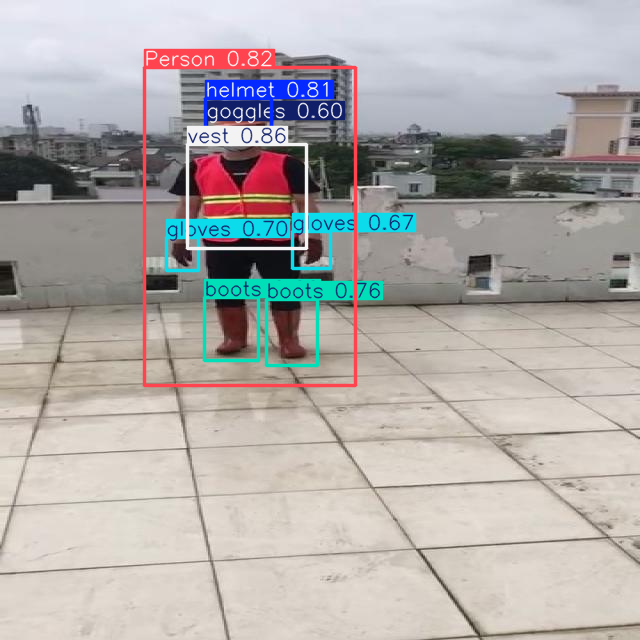

image1007.jpg | SAFE | workers: 1 | all PPE present


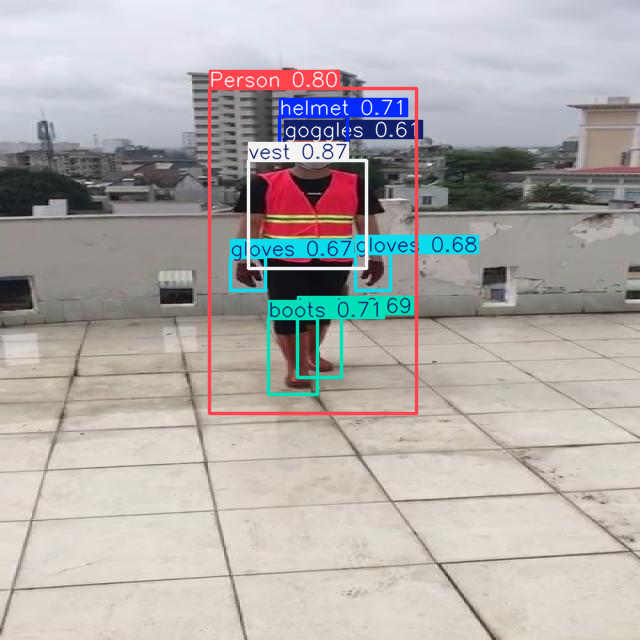

In [5]:
VIOLATIONS = {"no_helmet": "Missing helmet", "no_goggle": "Missing goggles",
              "no_gloves": "Missing gloves", "no_boots": "Missing boots"}

def check_site(image, conf=0.4):
    if not isinstance(image, str):
        image = image[:, :, ::-1]  # Gradio gives RGB, YOLO expects BGR
    r = best.predict(image, conf=conf, verbose=False)[0]
    labels = [r.names[int(c)] for c in r.boxes.cls]
    workers = labels.count("Person")
    issues = {}
    for l in labels:
        if l in VIOLATIONS:
            issues[VIOLATIONS[l]] = issues.get(VIOLATIONS[l], 0) + 1
    verdict = "UNSAFE" if issues else "SAFE"
    return r.plot()[:, :, ::-1], verdict, workers, issues

import glob
from PIL import Image as PILImage
for path in sorted(glob.glob("/content/**/construction-ppe/images/test/*", recursive=True))[:4]:
    img, verdict, workers, issues = check_site(path)
    print(path.split("/")[-1], "|", verdict, "| workers:", workers, "|", issues or "all PPE present")
    display(PILImage.fromarray(img).resize((640, int(640 * img.shape[0] / img.shape[1]))))

## 5. Demo app
Upload a photo or use your webcam. Colab prints a public `gradio.live` link you can open on your phone.

In [6]:
import gradio as gr

def ui(image, conf):
    img, verdict, workers, issues = check_site(image, conf)
    lines = [f"Verdict: {'✅ SAFE' if verdict == 'SAFE' else '⚠️ UNSAFE'}", f"Workers detected: {workers}"]
    lines += [f"• {k}: {v}" for k, v in issues.items()] or ["• All detected workers wear required PPE"]
    return img, "\n".join(lines)

gr.Interface(
    fn=ui,
    inputs=[gr.Image(type="numpy", sources=["upload", "webcam"], label="Site photo"),
            gr.Slider(0.1, 0.9, value=0.4, step=0.05, label="Confidence")],
    outputs=[gr.Image(label="Detections"), gr.Textbox(label="Safety report", lines=6)],
    title="Construction Safety PPE Checker",
    description="YOLOv8n fine-tuned on Construction-PPE. Detects helmets, vests, gloves, boots, goggles and missing PPE.",
).launch(share=True, debug=False)

Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://9e72b83b95eeaa62c1.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


## 6. Export and download
`best.pt` for Python, `best.onnx` to run on a Mac without a GPU (works with old Intel Macs too).

In [7]:
best.export(format="onnx", imgsz=640)
!cd {RUN_DIR} && zip -qr /content/ppe_model.zip weights results.png confusion_matrix_normalized.png
from google.colab import files
files.download("/content/ppe_model.zip")

Ultralytics 8.4.179 🚀 Python-3.13.15 torch-2.11.0+cu130 CPU (Intel Xeon CPU @ 2.00GHz)
💡 ProTip: Export to OpenVINO format for best performance on Intel hardware. Learn more at https://docs.ultralytics.com/integrations/openvino
Model summary (fused): 73 layers, 3,135,137 parameters, 0 gradients, 8.7 GFLOPs

PyTorch: starting from '/content/runs/detect/ppe/yolov8n/weights/best.pt' with input shape (1, 3, 640, 640) BCHW and output shape(s) (1, 15, 8400) (6.2 MB)
requirements: Ultralytics requirements ['onnx>=1.12.0,<2.0.0', 'onnxruntime', 'onnxslim>=0.1.82'] not found, attempting AutoUpdate...
Using Python 3.13.15 environment at: /usr
Resolved 12 packages in 289ms
Prepared 4 packages in 520ms
Installed 4 packages in 34ms
 + colorama==0.4.6
 + onnx==1.23.2
 + onnxruntime==1.31.0
 + onnxslim==0.1.98

requirements: AutoUpdate success ✅ 1.2s
WARNING ⚠️ requirements: Restart runtime or rerun command for updates to take effect


ONNX: starting export with onnx 1.23.2 opset 18...
ONNX: slimming

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## Run it on your laptop (optional)
```bash
pip install ultralytics
yolo predict model=best.onnx source=0 show=True   # 0 = webcam
```